# 01 — Chuẩn bị đầu vào KNN

Dùng cùng ảnh RGB 224×224 cho các nhánh HSV12, HOG và kết hợp. Bước này tạo danh sách ảnh, kiểm tra cách đọc và minh họa resize; chưa trích feature hay huấn luyện. Không đọc test.

In [1]:
from pathlib import Path
import sys
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path(r"C:\CS231")
DATA_ROOT = PROJECT_ROOT / "DATA"
OUTPUT = PROJECT_ROOT / "src" / "KNN" / "results_224" / "inputs"
OUTPUT.mkdir(parents=True, exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing import read_rgb224

CLASSES = [10000, 20000, 50000, 100000, 200000, 500000]

## 1. Lập danh sách ảnh

Đi theo mệnh giá tăng dần và tên file tăng dần. Mỗi dòng ghi một đường dẫn tương đối theo DATA và nhãn VND. Ta chỉ giữ danh sách đường dẫn, không nạp toàn bộ ảnh vào RAM.

In [2]:
manifests = {}

for split in ["train", "dev"]:
    rows = []
    for denomination in CLASSES:
        folder = DATA_ROOT / split / str(denomination)
        for image_path in sorted(folder.glob("*.png")):
            rows.append({
                "relative_path": image_path.relative_to(DATA_ROOT).as_posix(),
                "label_vnd": denomination,
            })

    manifests[split] = pd.DataFrame(rows, columns=["relative_path", "label_vnd"])
    manifests[split].to_csv(OUTPUT / f"{split}_manifest.csv", index=False)

counts = pd.DataFrame({
    split: manifest.groupby("label_vnd").size().reindex(CLASSES, fill_value=0)
    for split, manifest in manifests.items()
})
counts.loc["Total"] = counts.sum()
counts.to_csv(OUTPUT / "image_counts.csv")
display(counts)

,train,dev
label_vnd,,
10000,2299,315
20000,1916,238
50000,1646,195
100000,1918,250
200000,2525,309
500000,2190,257
Total,12494,1564


## 2. Kiểm tra đầu vào từng ảnh

`read_rgb224` đọc ảnh bằng OpenCV, chuyển BGR sang RGB rồi resize trực tiếp bằng bilinear. Đầu ra vẫn là uint8 trong miền 0–255. Nếu ảnh không đọc được, phép xử lý báo lỗi để ta kiểm tra, không bỏ qua ảnh.

Đọc lần lượt toàn train/dev, mỗi lần chỉ giữ một ảnh. Bảng sau xác minh shape và dtype, không phải kiểm tra nhãn đúng/sai.

In [3]:
checks = []

for split, manifest in manifests.items():
    correct_format = 0
    for relative_path in manifest["relative_path"]:
        image = read_rgb224(DATA_ROOT / relative_path)
        if image.shape == (224, 224, 3) and image.dtype == np.uint8:
            correct_format += 1
        del image

    checks.append({
        "split": split,
        "images": len(manifest),
        "rgb224_uint8": correct_format,
        "all_correct_format": correct_format == len(manifest),
    })

checks = pd.DataFrame(checks)
checks.to_csv(OUTPUT / "input_checks.csv", index=False)
display(checks)

,split,images,rgb224_uint8,all_correct_format
0,train,12494,12494,True
1,dev,1564,1564,True


## 3. Xem ảnh trước và sau resize

Lấy ảnh đầu tiên của mỗi lớp trong train để minh họa. Resize trực tiếp giữ toàn bộ khung hình nhưng có thể làm thay đổi tỷ lệ hình dạng. 224×224 là lựa chọn đã audit, chưa được chứng minh tối ưu về điểm phân loại. Ảnh gốc trong hình được co vừa ô hiển thị.

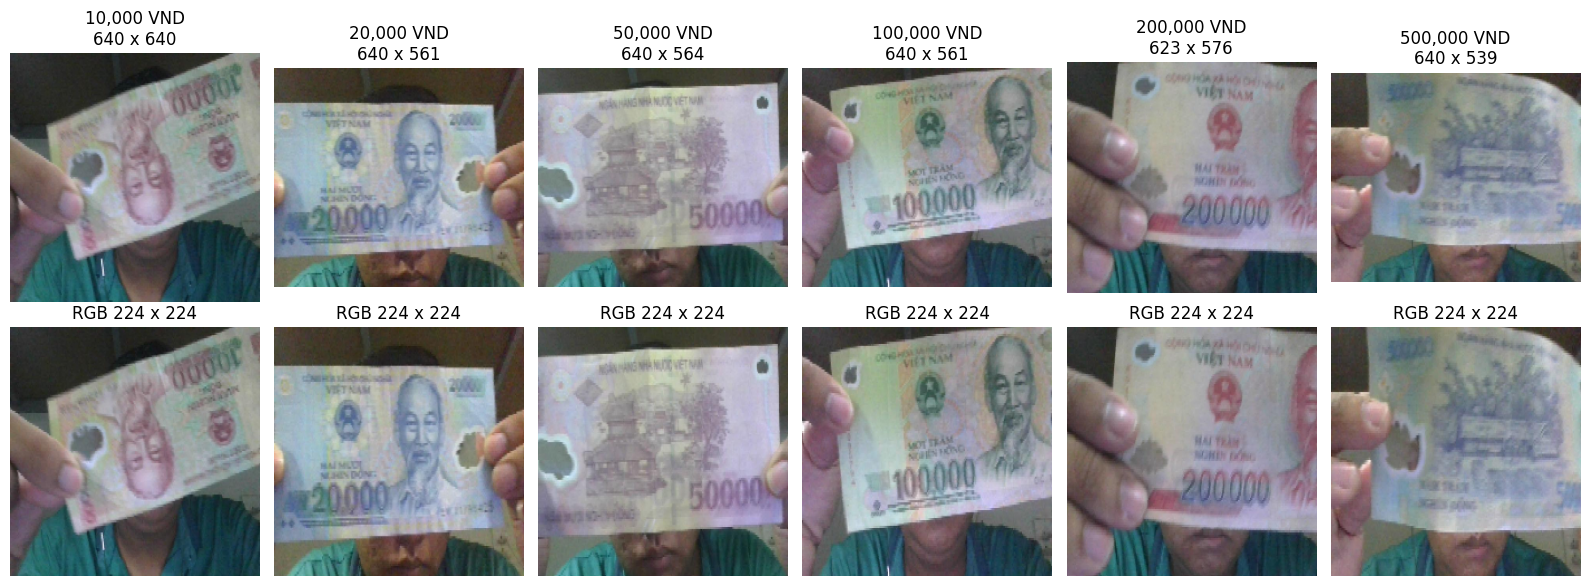

In [4]:
fig, axes = plt.subplots(2, 6, figsize=(16, 6))

for column, denomination in enumerate(CLASSES):
    manifest = manifests["train"]
    relative_path = manifest.loc[manifest["label_vnd"] == denomination, "relative_path"].iloc[0]
    image_path = DATA_ROOT / relative_path
    original = cv2.cvtColor(cv2.imread(str(image_path)), cv2.COLOR_BGR2RGB)
    resized = read_rgb224(image_path)

    axes[0, column].imshow(original)
    axes[0, column].set_title(f"{denomination:,} VND\n{original.shape[1]} x {original.shape[0]}")
    axes[1, column].imshow(resized)
    axes[1, column].set_title("RGB 224 x 224")
    axes[0, column].axis("off")
    axes[1, column].axis("off")

plt.tight_layout()
plt.savefig(OUTPUT / "rgb224_examples.png", dpi=150)
plt.show()

## 4. Ghi cấu hình để các bước sau dùng lại

Năm biến thể thuộc ba họ feature. Mỗi biến thể thử k từ 1 đến 10 và hai cách bỏ phiếu; dùng Euclidean cho cả vector gốc và PCA. Tổng cộng 100 cấu hình dev. PCA chỉ fit train, giữ 95% phương sai; số chiều sau PCA chưa biết ở bước này. Giữ 95% phương sai không có nghĩa giữ 95% khả năng phân loại.

In [5]:
config = {
    "classes_vnd": CLASSES,
    "splits": {"train": 12494, "dev": 1564, "test": 1553},
    "preprocessing": {
        "color": "RGB", "size": [224, 224], "dtype": "uint8",
        "resize": "direct", "library": "opencv", "interpolation": "INTER_LINEAR",
        "augmentation": False,
    },
    "hsv": {"bins": [12, 12, 12], "ranges": [0, 180, 0, 256, 0, 256], "normalization": "L2"},
    "hog": {
        "grayscale": True, "orientations": 9, "pixels_per_cell": [16, 16],
        "cells_per_block": [2, 2], "block_norm": "L2-Hys", "transform_sqrt": False,
        "dimensions_before_pca": 6084,
    },
    "pca": {"n_components": 0.95, "svd_solver": "full", "whiten": False, "fit_split": "train"},
    "hog_pipeline": "HOG -> optional PCA -> whole-vector L2",
    "fusion": "concatenate L2 HSV then L2 HOG branch; no additional weighting or normalization",
    "feature_dtype": "float32",
    "candidate_order": ["HSV12", "HOG", "HOG_PCA", "HSV12_HOG", "HSV12_HOG_PCA"],
    "knn": {"k": list(range(1, 11)), "weights": ["uniform", "distance"], "metric": "euclidean", "algorithm": "brute"},
    "selection": ["max unrounded macro_f1", "min unrounded mae_vnd", "candidate order then k then weights"],
    "test_history": "Previously evaluated and inspected; not an untouched holdout.",
    "versions": {"opencv": cv2.__version__, "numpy": np.__version__, "pandas": pd.__version__},
}

(OUTPUT / "experiment_config.json").write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8")
print("Đã lưu manifest, bảng kiểm tra, hình minh họa và cấu hình tại:", OUTPUT)

Đã lưu manifest, bảng kiểm tra, hình minh họa và cấu hình tại: C:\CS231\src\KNN\results_224\inputs


## Cần hiểu trước bước 2

- Vì sao phải chuyển BGR sang RGB?
- Vì sao các nhánh dùng cùng ảnh 224×224?
- Bilinear làm gì và resize trực tiếp có hạn chế gì?
- Vì sao chưa chia pixel cho 255 trước histogram HSV?
- Vì sao không nạp toàn bộ ảnh cùng lúc?

Bước tiếp theo là trích HSV12 từ manifest đã lưu. Chỉ bắt đầu khi bạn hiểu được các thao tác ở notebook này.